In [51]:
import pandas as pd
import numpy as np
from pathlib import Path

In [52]:
df_2015 = pd.read_excel('../data/raw/2015.xlsx')
df_2016 = pd.read_excel('../data/raw/2016.xlsx')
df_2017 = pd.read_excel('../data/raw/2017.xlsx')
df_2018 = pd.read_excel('../data/raw/2018.xlsx')
df_2019 = pd.read_excel('../data/raw/2019.xlsx')
df_2020 = pd.read_excel('../data/raw/2020.xlsx')
df_2021 = pd.read_excel('../data/raw/2021.xlsx')
df_2022 = pd.read_excel('../data/raw/2022.xlsx')
df_2023 = pd.read_excel('../data/raw/2023.xlsx')
df_2024 = pd.read_excel('../data/raw/2024.xlsx')
df_left = pd.concat([df_2015, df_2016, df_2017, df_2018, df_2019, df_2020, df_2021, df_2022, df_2023 ,df_2024])
print(df_left.head())



/opt/miniconda3/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/opt/miniconda3/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


   ATP  Location              Tournament       Date  Series    Court Surface  \
0    1  Brisbane  Brisbane International 2015-01-05  ATP250  Outdoor    Hard   
1    1  Brisbane  Brisbane International 2015-01-05  ATP250  Outdoor    Hard   
2    1  Brisbane  Brisbane International 2015-01-05  ATP250  Outdoor    Hard   
3    1  Brisbane  Brisbane International 2015-01-05  ATP250  Outdoor    Hard   
4    1  Brisbane  Brisbane International 2015-01-06  ATP250  Outdoor    Hard   

       Round  Best of         Winner  ...   EXW   EXL   LBW   LBL   PSW   PSL  \
0  1st Round      3.0   Duckworth J.  ...  4.30  1.20  4.33  1.20  4.67  1.23   
1  1st Round      3.0  Kokkinakis T.  ...  2.60  1.48  2.62  1.44  2.67  1.53   
2  1st Round      3.0      Chardy J.  ...  1.33  3.20  1.33  3.25  1.34  3.50   
3  1st Round      3.0       Tomic B.  ...  1.60  2.30  1.62  2.20  1.65  2.37   
4  1st Round      3.0   Kukushkin M.  ...  1.50  2.50  1.44  2.62  1.48  2.84   

   MaxW  MaxL  AvgW  AvgL  
0  4

In [53]:
df_right = pd.read_csv('../data/processed/model_ready/features_no_ytd.csv')

In [54]:

# ============================================================================
# HELPER FUNCTION
# ============================================================================

def create_normalized_match_id_winner_loser(row):
    """Create normalized match_id from Winner/Loser format"""
    date = str(row['Date'])
    w = str(row['Winner']).strip().replace(' ', '').replace('.', '')
    l = str(row['Loser']).strip().replace(' ', '').replace('.', '')
    # Sort alphabetically - consistent ID
    names_sorted = '_'.join(sorted([w, l]))
    return f"{date}_{names_sorted}"

# ============================================================================
# SIMPLE MERGE USING NORMALIZED MATCH_ID
# ============================================================================

print("="*80)
print("MERGING ODDS DATA WITH FEATURES USING NORMALIZED MATCH_ID")
print("="*80)

# Standardize dates
df_left['Date'] = pd.to_datetime(df_left['Date']).dt.strftime('%Y-%m-%d')
df_right['Date'] = pd.to_datetime(df_right['Date']).dt.strftime('%Y-%m-%d')

# Create normalized match_id for BOTH
print("\nCreating match_ids...")
df_left['match_id'] = df_left.apply(create_normalized_match_id_winner_loser, axis=1)
df_right['match_id'] = df_right.apply(create_normalized_match_id_winner_loser, axis=1)

print(f"df_left unique matches: {df_left['match_id'].nunique()}")
print(f"df_right unique matches: {df_right['match_id'].nunique()}")

# SIMPLE MERGE on match_id
print("\nMerging...")
result = pd.merge(
    df_right,  # Features (Elo, form, etc.)
    df_left[['match_id', 'B365W', 'B365L', 'PSW', 'PSL', 'MaxW', 'MaxL', 'AvgW', 'AvgL']],  # Just odds columns
    on='match_id',
    how='left'
)

print(f"\n✓ Merged: {result.shape}")

# Check match rate
matched = result['AvgW'].notna().sum()
print(f"  Matched: {matched} / {len(result)} ({matched/len(result)*100:.1f}%)")
print(f"  Unmatched: {result['AvgW'].isna().sum()}")

print("\nSample of merged data:")
print(result[['Date', 'Winner', 'Loser', 'elo_winner', 'AvgW', 'AvgL']].head())

print(f"\nColumns in result ({len(result.columns)}):")
print(result.columns.tolist())

MERGING ODDS DATA WITH FEATURES USING NORMALIZED MATCH_ID

Creating match_ids...
df_left unique matches: 24930
df_right unique matches: 24864

Merging...

✓ Merged: (24875, 40)
  Matched: 24874 / 24875 (100.0%)
  Unmatched: 1

Sample of merged data:
         Date            Winner              Loser   elo_winner  AvgW  AvgL
0  2015-01-05         Chardy J.         Golubev A.  2161.852551  1.32  3.30
1  2015-01-05         Muller G.  Roger-Vasselin E.  2159.069302  1.73  2.05
2  2015-01-05  Haider-Maurer A.      Granollers M.  1964.068655  2.71  1.44
3  2015-01-05          Coric B.           Haase R.  1734.294841  1.72  2.07
4  2015-01-05        Bolelli S.          Becker B.  2152.516157  2.15  1.67

Columns in result (40):
['ATP', 'Location', 'Tournament', 'Date', 'Series', 'Court', 'Surface', 'Round', 'Best of', 'Winner', 'Loser', 'WRank', 'LRank', 'WPts', 'LPts', 'elo_winner', 'elo_loser', 'proba_elo', 'Winner_hand', 'Winner_height', 'Winner_age', 'Loser_hand', 'Loser_height', 'Loser_a

In [55]:
print(result)

       ATP  Location              Tournament        Date       Series  \
0        1  Brisbane  Brisbane International  2015-01-05       ATP250   
1        2   Chennai            Chennai Open  2015-01-05       ATP250   
2        2   Chennai            Chennai Open  2015-01-05       ATP250   
3        2   Chennai            Chennai Open  2015-01-05       ATP250   
4        3      Doha  Qatar Exxon Mobil Open  2015-01-05       ATP250   
...    ...       ...                     ...         ...          ...   
24870   65     Turin             Masters Cup  2024-11-15  Masters Cup   
24871   65     Turin             Masters Cup  2024-11-15  Masters Cup   
24872   65     Turin             Masters Cup  2024-11-16  Masters Cup   
24873   65     Turin             Masters Cup  2024-11-16  Masters Cup   
24874   65     Turin             Masters Cup  2024-11-17  Masters Cup   

         Court Surface        Round  Best of            Winner  ... form_diff  \
0      Outdoor    Hard    1st Round      3

In [56]:
out_dir = Path("../data/processed/model_ready")
out_dir.mkdir(parents=True, exist_ok=True)

result.to_csv(out_dir / 'result.csv')

print(result.describe())

                ATP       Best of         WRank         LRank          WPts  \
count  24875.000000  24860.000000  24864.000000  24821.000000  24865.000000   
mean      32.242372      3.397506     59.220922     89.968374   1931.609531   
std       18.184862      0.798139     72.472185    124.686895   2222.730342   
min        1.000000      3.000000      1.000000      1.000000      1.000000   
25%       18.000000      3.000000     17.000000     34.000000    725.000000   
50%       32.000000      3.000000     42.000000     63.000000   1093.000000   
75%       49.000000      3.000000     78.000000    102.000000   2130.000000   
max       68.000000      5.000000   1821.000000   4915.000000  16950.000000   

               LPts    elo_winner     elo_loser     proba_elo  Winner_height  \
count  24821.000000  24875.000000  24875.000000  24875.000000   22996.000000   
mean    1188.240240   1642.476933   1583.465129      0.569785     187.637676   
std     1262.064659    153.488395    120.132286 

In [57]:
# ============================================================================
# MERGE TEST PREDICTIONS WITH BETTING ODDS
# ============================================================================

print("="*80)
print("MERGING TEST PREDICTIONS WITH BETTING ODDS")
print("="*80)

# Load predictions (test set only, with model predictions)
predictions = pd.read_csv('../data/processed/model_ready/ALL_PREDICTIONS_WITH_IDS.csv')

print(f"Predictions: {predictions.shape}")
print(f"Columns: {predictions.columns.tolist()[:15]}...")

# Load odds data (24,930 matches with odds)
odds_data = df_left.copy()  # Your odds data (already loaded)

# Create normalized match_id for predictions
def create_normalized_match_id_player(row):
    """For player_name/opponent_name format"""
    date = str(row['Date'])
    p1 = str(row['player_name']).strip().replace(' ', '').replace('.', '')
    p2 = str(row['opponent_name']).strip().replace(' ', '').replace('.', '')
    names_sorted = '_'.join(sorted([p1, p2]))
    return f"{date}_{names_sorted}"

predictions['match_id_normalized'] = predictions.apply(create_normalized_match_id_player, axis=1)

# Create normalized match_id for odds
def create_normalized_match_id_winner(row):
    """For Winner/Loser format"""
    date = str(row['Date'])
    w = str(row['Winner']).strip().replace(' ', '').replace('.', '')
    l = str(row['Loser']).strip().replace(' ', '').replace('.', '')
    names_sorted = '_'.join(sorted([w, l]))
    return f"{date}_{names_sorted}"

odds_data['Date'] = pd.to_datetime(odds_data['Date']).dt.strftime('%Y-%m-%d')
odds_data['match_id_normalized'] = odds_data.apply(create_normalized_match_id_winner, axis=1)

# MERGE
merged = pd.merge(
    predictions,
    odds_data[['match_id_normalized', 'AvgW', 'AvgL', 'MaxW', 'MaxL']],
    on='match_id_normalized',
    how='left'
)

print(f"\n✓ Merged: {merged.shape}")
print(f"  Matched: {merged['AvgW'].notna().sum()} / {len(merged)} ({merged['AvgW'].notna().sum()/len(merged)*100:.1f}%)")

print("\nSample:")
print(merged[['Date', 'player_name', 'opponent_name', 'prob_CatBoost', 'AvgW']].head())

MERGING TEST PREDICTIONS WITH BETTING ODDS
Predictions: (9952, 38)
Columns: ['Date', 'player_name', 'opponent_name', 'match_id', 'player_elo', 'opponent_elo', 'player_rank', 'opponent_rank', 'won', 'y_true', 'prob_Baseline_Elo', 'pred_Baseline_Elo', 'prob_Logistic_Regression', 'pred_Logistic_Regression', 'prob_Logistic_Regression_No_MC']...

✓ Merged: (9952, 43)
  Matched: 9950 / 9952 (100.0%)

Sample:
         Date       player_name opponent_name  prob_CatBoost  AvgW
0  2015-01-06         Jaziri M.      Souza J.       0.406315  2.31
1  2015-01-06  Kohlschreiber P.   Struff J.L.       0.664947  3.09
2  2015-01-06          Vanni L.   Berankis R.       0.624390  1.31
3  2015-01-06     Ramanathan R.        Ito T.       0.185142  1.37
4  2015-01-06          Kudla D.   Nieminen J.       0.592212  1.65


In [58]:
# ============================================================================
# ADD MARKET ANALYSIS COLUMNS (Add this after your merge)
# ============================================================================

print("\n" + "="*80)
print("CALCULATING MARKET PROBABILITIES AND EDGE")
print("="*80)

# You already have 'merged' from previous cell with predictions + odds

# Calculate market probability (perspective-aware)
merged['market_prob'] = np.where(
    merged['won'] == 1,
    1 / merged['AvgW'],  # Winner perspective: use winner odds
    1 / merged['AvgL']   # Loser perspective: use loser odds
)

# Model probability
merged['model_prob'] = merged['prob_CatBoost']

# Edge
merged['edge'] = merged['model_prob'] - merged['market_prob']

print(f"✓ Calculated market_prob, model_prob, edge")

# ============================================================================
# VERIFICATION
# ============================================================================

# Remove rows without odds
merged_clean = merged[merged['AvgW'].notna() & merged['AvgL'].notna()].copy()

print(f"\nTotal merged: {len(merged)} rows")
print(f"With odds: {len(merged_clean)} rows")
print(f"Missing odds: {len(merged) - len(merged_clean)}")

print(f"\nCleaned dataset:")
print(f"  Winners: {(merged_clean['won']==1).sum()}")
print(f"  Losers: {(merged_clean['won']==0).sum()}")

print(f"\nModel prob averages:")
print(f"  Overall: {merged_clean['model_prob'].mean():.3f} (should be ~0.50)")
print(f"  Winners: {merged_clean[merged_clean['won']==1]['model_prob'].mean():.3f} (should be 0.68-0.75)")
print(f"  Losers: {merged_clean[merged_clean['won']==0]['model_prob'].mean():.3f} (should be 0.25-0.32)")

# LOG LOSS COMPARISON
from sklearn.metrics import log_loss

model_ll = log_loss(merged_clean['y_true'], merged_clean['model_prob'])
market_ll = log_loss(merged_clean['y_true'], merged_clean['market_prob'])

print(f"\nModel log loss: {model_ll:.4f}")
print(f"Market log loss: {market_ll:.4f}")
improvement = ((market_ll - model_ll) / market_ll) * 100
print(f"Improvement: {improvement:+.1f}%")

merged = merged_clean.copy()


CALCULATING MARKET PROBABILITIES AND EDGE
✓ Calculated market_prob, model_prob, edge

Total merged: 9952 rows
With odds: 9950 rows
Missing odds: 2

Cleaned dataset:
  Winners: 4975
  Losers: 4975

Model prob averages:
  Overall: 0.500 (should be ~0.50)
  Winners: 0.647 (should be 0.68-0.75)
  Losers: 0.352 (should be 0.25-0.32)

Model log loss: 0.5227
Market log loss: 0.5787
Improvement: +9.7%


In [59]:
# Export merged dataset with market analysis
merged.to_csv('../data/processed/model_ready/merged_predictions_odds.csv', index=False)

In [60]:
# Check if predictions really has 2 perspectives per match
print(f"Total predictions rows: {len(predictions)}")
print(f"Unique normalized match_ids: {predictions['match_id_normalized'].nunique()}")
print(f"Expected if 2 per match: {len(predictions) / 2}")

# Check value counts
match_counts = predictions['match_id_normalized'].value_counts()
print(f"\nMatches with 2 perspectives: {(match_counts == 2).sum()}")
print(f"Matches with 1 perspective: {(match_counts == 1).sum()}")
print(f"Matches with >2 perspectives: {(match_counts > 2).sum()}")

# Show some examples with only 1 perspective
single_perspective = match_counts[match_counts == 1].head(5)
print(f"\nExample matches with only 1 perspective:")
for match_id in single_perspective.index:
    match_rows = predictions[predictions['match_id_normalized'] == match_id]
    print(f"  {match_id}: {len(match_rows)} row(s)")
    print(match_rows[['player_name', 'opponent_name', 'won']])

Total predictions rows: 9952
Unique normalized match_ids: 4973
Expected if 2 per match: 4976.0

Matches with 2 perspectives: 4970
Matches with 1 perspective: 0
Matches with >2 perspectives: 3

Example matches with only 1 perspective:


In [61]:
# Check if a few huge wins are driving everything
returns_array = np.array(returns)

print(f"\nReturns distribution:")
print(f"  Mean: {returns_array.mean():.3f}")
print(f"  Median: {np.median(returns_array):.3f}")
print(f"  Std: {returns_array.std():.3f}")
print(f"  Min: {returns_array.min():.2f}")
print(f"  Max: {returns_array.max():.2f}")

# Check for extreme outliers
big_wins = returns_array[returns_array > 5]
print(f"\nBig wins (>500% return): {len(big_wins)}")
if len(big_wins) > 0:
    print(f"  Examples: {big_wins[:5]}")

# Recalculate Sharpe more carefully
# Annualization: ~340 bets/year
annual_factor = np.sqrt(len(returns)/10)
sharpe_corrected = (returns_array.mean() / returns_array.std()) * annual_factor

print(f"\nSharpe calculation:")
print(f"  Mean return: {returns_array.mean():.4f}")
print(f"  Std return: {returns_array.std():.4f}")
print(f"  Annual factor: {annual_factor:.2f}")
print(f"  Sharpe: {sharpe_corrected:.2f}")

# Conservative Sharpe (using fewer bets/year assumption)
sharpe_conservative = (returns_array.mean() / returns_array.std()) * np.sqrt(50)
print(f"  Sharpe (conservative, assuming 50 bets/yr): {sharpe_conservative:.2f}")


Returns distribution:
  Mean: 0.370
  Median: 0.370
  Std: 3.092
  Min: -1.00
  Max: 160.00

Big wins (>500% return): 38
  Examples: [ 5.98 12.04  7.06 10.08  7.72]

Sharpe calculation:
  Mean return: 0.3700
  Std return: 3.0921
  Annual factor: 18.50
  Sharpe: 2.21
  Sharpe (conservative, assuming 50 bets/yr): 0.85


In [63]:
# ============================================================================
# MANUAL PREPARATION (SKIP THE FUNCTION!)
# ============================================================================

# Start fresh
comparison = merged.copy()

# Remove duplicate columns FIRST
comparison = comparison.loc[:, ~comparison.columns.duplicated()]
comparison = comparison.reset_index(drop=True)

print(f"Cleaned: {comparison.shape}")
print(f"Columns: {comparison.columns.tolist()}")

# Check if we have what we need
required = ['y_true', 'prob_CatBoost', 'market_prob', 'AvgW', 'AvgL', 'won']
missing = [c for c in required if c not in comparison.columns]
if missing:
    print(f"Missing columns: {missing}")
else:
    print("✓ All required columns present")

# Simple setup
comparison['actual_outcome'] = comparison['y_true']
comparison['model_prob'] = comparison['prob_CatBoost']
comparison['edge'] = comparison['model_prob'] - comparison['market_prob']

# Decimal odds
comparison['decimal_odds'] = np.where(
    comparison['won'] == 1,
    comparison['AvgW'],
    comparison['AvgL']
)

# Use unique matches
comparison_unique = comparison.drop_duplicates(subset='match_id', keep='first').reset_index(drop=True)

Cleaned: (9950, 46)
Columns: ['Date', 'player_name', 'opponent_name', 'match_id', 'player_elo', 'opponent_elo', 'player_rank', 'opponent_rank', 'won', 'y_true', 'prob_Baseline_Elo', 'pred_Baseline_Elo', 'prob_Logistic_Regression', 'pred_Logistic_Regression', 'prob_Logistic_Regression_No_MC', 'pred_Logistic_Regression_No_MC', 'prob_Random_Forest', 'pred_Random_Forest', 'prob_Gradient_Boosting', 'pred_Gradient_Boosting', 'prob_XGBoost_Tuned', 'pred_XGBoost_Tuned', 'prob_DecisionTree', 'pred_DecisionTree', 'prob_KNN_k=10', 'pred_KNN_k=10', 'prob_RandomForest_w_GridSearch', 'pred_RandomForest_w_GridSearch', 'prob_Lasso (alpha=0.1)', 'pred_Lasso (alpha=0.1)', "prob_Lasso, 'no multicollinearity' (alpha=0.1)", "pred_Lasso, 'no multicollinearity' (alpha=0.1)", 'prob_CatBoost', 'pred_CatBoost', 'prob_Ensemble_Model', 'pred_Ensemble_Model', 'prob_Ensemble_Diverse', 'pred_Ensemble_Diverse', 'match_id_normalized', 'AvgW', 'AvgL', 'MaxW', 'MaxL', 'market_prob', 'model_prob', 'edge']
✓ All required 

In [64]:
# =====================================
# SIMULATION 1: FIXED STAKE BETTING
# =====================================

def simulate_fixed_stake_betting(comparison, threshold=0.05, stake=100, use_best_odds=False):
    """
    Fixed stake betting with comprehensive statistics
    """
    # USE UNIQUE MATCHES ONLY (one bet per match)
    comparison_unique = comparison.drop_duplicates(subset='match_id', keep='first')
    
    # Select matches where edge exceeds threshold
    bets = comparison_unique[comparison_unique['edge'] > threshold].copy()
    
    if len(bets) == 0:
        return {
            'threshold': threshold,
            'num_bets': 0,
            'total_profit': 0,
            'total_staked': 0,
            'roi': 0,
            'win_rate': 0,
            'sharpe_ratio': 0,
            'max_drawdown': 0
        }
    
    # Calculate profits
    odds_col = 'best_decimal_odds' if use_best_odds else 'decimal_odds'
    bets['profit'] = np.where(
        bets['actual_outcome'] == 1,
        stake * (bets[odds_col] - 1),
        -stake
    )
    
    # Calculate cumulative metrics
    bets['cumulative_profit'] = bets['profit'].cumsum()
    bets['cumulative_staked'] = stake * (np.arange(len(bets)) + 1)
    
    # Calculate statistics
    total_profit = bets['profit'].sum()
    total_staked = stake * len(bets)
    roi = (total_profit / total_staked) * 100 if total_staked > 0 else 0
    win_rate = (bets['actual_outcome'] == 1).mean()
    
    # Sharpe ratio (annualized, assuming daily betting)
    returns = bets['profit'] / stake
    sharpe_ratio = np.sqrt(252) * returns.mean() / returns.std() if returns.std() > 0 else 0
    
    # Maximum drawdown
    cummax = bets['cumulative_profit'].cummax()
    drawdown = cummax - bets['cumulative_profit']
    max_drawdown = drawdown.max()
    
    return {
        'threshold': threshold,
        'num_bets': len(bets),
        'total_profit': total_profit,
        'total_staked': total_staked,
        'roi': roi,
        'win_rate': win_rate,
        'sharpe_ratio': sharpe_ratio,
        'max_drawdown': max_drawdown,
        'avg_odds': bets[odds_col].mean() if len(bets) > 0 else 0,
        'bets_df': bets
    }

In [65]:
# =====================================
# SIMULATION 2: KELLY CRITERION
# =====================================

def calculate_kelly_fraction(model_prob, market_prob):
    """
    Calculate Kelly fraction with comprehensive safety checks
    """
    # Input validation
    if pd.isna(model_prob) or pd.isna(market_prob):
        return 0
    
    # Probability range validation
    if market_prob <= 0.01 or market_prob >= 0.99:
        return 0
    if model_prob <= 0 or model_prob >= 1:
        return 0
    
    # No bet if no positive edge
    if model_prob <= market_prob:
        return 0
    
    # Calculate Kelly with caps
    decimal_odds = min(1 / market_prob, 100)  # Cap at 100:1
    b = decimal_odds - 1
    p = model_prob
    q = 1 - p
    
    kelly = (b * p - q) / b
    
    # Cap Kelly fraction at 25% (very aggressive already)
    kelly = max(0, min(kelly, 0.25))
    
    return kelly

def simulate_kelly_betting(comparison, bankroll=10000, kelly_multiplier=0.25, min_kelly=0.01):
    """
    Kelly Criterion betting with proper bankroll management
    """
    # Calculate Kelly fractions
    comparison = comparison.copy()
    comparison['kelly_fraction'] = comparison.apply(
        lambda row: calculate_kelly_fraction(row['model_prob'], row['market_prob']),
        axis=1
    )
    
    # Filter for minimum Kelly
    kelly_bets = comparison[comparison['kelly_fraction'] >= min_kelly].copy()
    
    if len(kelly_bets) == 0:
        return {
            'num_bets': 0,
            'starting_bankroll': bankroll,
            'final_bankroll': bankroll,
            'total_profit': 0,
            'roi': 0,
            'kelly_multiplier': kelly_multiplier,
            'max_drawdown': 0,
            'max_drawdown_pct': 0
        }
    
    # Simulate sequential betting
    current_bankroll = bankroll
    bankroll_history = [bankroll]
    bet_history = []
    
    for idx, row in kelly_bets.iterrows():
        # Stop if bankrupt
        if current_bankroll <= 0:
            break
        
        # Calculate bet size (with additional safety caps)
        kelly_frac = row['kelly_fraction'] * kelly_multiplier
        kelly_frac = min(kelly_frac, 0.1)  # Max 10% after multiplier
        
        bet_amount = current_bankroll * kelly_frac
        bet_amount = min(bet_amount, current_bankroll * 0.1)  # Double-check
        
        # Calculate outcome
        decimal_odds = min(row['decimal_odds'], 100)
        
        if row['actual_outcome'] == 1:
            profit = bet_amount * (decimal_odds - 1)
        else:
            profit = -bet_amount
        
        # Update bankroll
        current_bankroll += profit
        bankroll_history.append(current_bankroll)
        
        bet_history.append({
            'bet_num': len(bet_history) + 1,
            'bet_amount': bet_amount,
            'kelly_fraction': row['kelly_fraction'],
            'profit': profit,
            'bankroll': current_bankroll
        })
    
    # Calculate metrics
    total_profit = current_bankroll - bankroll
    roi = (total_profit / bankroll) * 100
    
    # Maximum drawdown
    bankroll_array = np.array(bankroll_history)
    cummax = np.maximum.accumulate(bankroll_array)
    drawdown = cummax - bankroll_array
    max_drawdown = drawdown.max()
    max_drawdown_pct = (max_drawdown / bankroll) * 100
    
    return {
        'num_bets': len(bet_history),
        'starting_bankroll': bankroll,
        'final_bankroll': current_bankroll,
        'total_profit': total_profit,
        'roi': roi,
        'kelly_multiplier': kelly_multiplier,
        'max_drawdown': max_drawdown,
        'max_drawdown_pct': max_drawdown_pct,
        'bankroll_history': bankroll_history,
        'bet_history': pd.DataFrame(bet_history) if bet_history else pd.DataFrame()
    }

# =====================================
# MAIN ANALYSIS FUNCTION
# =====================================

def run_complete_betting_analysis(df):
    """
    Run all three betting simulations with visualizations
    """
    
    # Initialize variables for later use
    best_roi = None
    best_sharpe = None
    
    # ========================================
    # SIMULATION 1: FIXED STAKE ANALYSIS
    # ========================================
    print("\n" + "="*80)
    print("SIMULATION 1: FIXED STAKE BETTING - MULTIPLE THRESHOLDS")
    print("="*80)
    
    thresholds = [0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.12, 0.15, 0.20]
    threshold_results = []
    
    print(f"\n{'Threshold':>10s} {'Bets':>8s} {'Profit':>12s} {'ROI':>8s} {'Win Rate':>10s} {'Sharpe':>8s} {'Max DD':>10s}")
    print("-" * 85)
    
    for thresh in thresholds:
        result = simulate_fixed_stake_betting(comparison, threshold=thresh, stake=100)
        
        if result['num_bets'] > 0:
            threshold_results.append(result)
            print(f"{thresh:>10.2f} {result['num_bets']:>8d} "
                  f"${result['total_profit']:>11.2f} {result['roi']:>7.2f}% "
                  f"{result['win_rate']:>9.1%} {result['sharpe_ratio']:>7.2f} "
                  f"${result['max_drawdown']:>9.2f}")
    
    # Find optimal thresholds
    threshold_df = None
    if threshold_results:
        threshold_df = pd.DataFrame([
            {k: v for k, v in r.items() if k != 'bets_df'} 
            for r in threshold_results
        ])
        
        best_roi_idx = threshold_df['roi'].idxmax()
        best_roi = threshold_df.iloc[best_roi_idx]
        
        # Filter for minimum number of bets (at least 20)
        viable_thresholds = threshold_df[threshold_df['num_bets'] >= 20]
        
        if not viable_thresholds.empty:
            best_sharpe_idx = viable_thresholds['sharpe_ratio'].idxmax()
            best_sharpe = viable_thresholds.iloc[best_sharpe_idx]
        else:
            best_sharpe = best_roi
        
        print(f"\n✓ Best ROI: threshold={best_roi['threshold']:.2f}, "
              f"ROI={best_roi['roi']:.2f}%, Bets={int(best_roi['num_bets'])}")
        print(f"✓ Best Sharpe: threshold={best_sharpe['threshold']:.2f}, "
              f"Sharpe={best_sharpe['sharpe_ratio']:.2f}, Bets={int(best_sharpe['num_bets'])}")
    
    # ========================================
    # SIMULATION 2: KELLY CRITERION
    # ========================================
    print("\n" + "="*80)
    print("SIMULATION 2: KELLY CRITERION ANALYSIS")
    print("="*80)
    
    # Calculate Kelly statistics
    comparison['kelly_fraction'] = comparison.apply(
        lambda row: calculate_kelly_fraction(row['model_prob'], row['market_prob']),
        axis=1
    )
    
    kelly_positive = comparison[comparison['kelly_fraction'] > 0]
    
    print(f"\nKelly Fraction Statistics:")
    print(f"  Matches with positive Kelly: {len(kelly_positive)} ({len(kelly_positive)/len(comparison)*100:.1f}%)")
    
    # Calculate median for later use
    kelly_median = kelly_positive['kelly_fraction'].median() if len(kelly_positive) > 0 else 0
    
    if len(kelly_positive) > 0:
        print(f"  Mean Kelly fraction: {kelly_positive['kelly_fraction'].mean():.4f}")
        print(f"  Median Kelly fraction: {kelly_median:.4f}")
        print(f"  95th percentile: {kelly_positive['kelly_fraction'].quantile(0.95):.4f}")
        
        print(f"\nTop 5 Kelly Recommendations:")
        top_kelly = kelly_positive.nlargest(5, 'kelly_fraction')[
            ['model_prob', 'market_prob', 'edge', 'kelly_fraction', 'actual_outcome']
        ].round(3)
        print(top_kelly.to_string())
    
    # Test different Kelly multipliers
    print("\n" + "-"*80)
    print("KELLY BETTING SIMULATION (Starting bankroll: $10,000)")
    print("-"*80)
    
    kelly_multipliers = [0.1, 0.25, 0.5, 0.75, 1.0]
    kelly_results = []
    
    print(f"\n{'Kelly Mult':>12s} {'Bets':>8s} {'Final Bank':>12s} {'Profit':>12s} {'ROI':>8s} {'Max DD %':>10s}")
    print("-" * 75)
    
    for mult in kelly_multipliers:
        result = simulate_kelly_betting(comparison, bankroll=10000, kelly_multiplier=mult)
        
        if result['num_bets'] > 0:
            kelly_results.append(result)
            
            # Check for unrealistic results
            if abs(result['roi']) > 10000:
                print(f"{mult:>12.2f} {result['num_bets']:>8d} "
                      f"ERROR: Unrealistic ROI detected")
            else:
                print(f"{mult:>12.2f} {result['num_bets']:>8d} "
                      f"${result['final_bankroll']:>11,.2f} "
                      f"${result['total_profit']:>11,.2f} "
                      f"{result['roi']:>7.2f}% "
                      f"{result['max_drawdown_pct']:>9.2f}%")
    
    # ========================================
    # SIMULATION 3: OPTIMAL THRESHOLD FINDING
    # ========================================
    print("\n" + "="*80)
    print("SIMULATION 3: OPTIMAL THRESHOLD ANALYSIS")
    print("="*80)
    
    # Fine-grained threshold search
    fine_thresholds = np.linspace(0, 0.2, 41)  # 0 to 20% in 0.5% steps
    fine_results = []
    
    for thresh in fine_thresholds:
        result = simulate_fixed_stake_betting(comparison, threshold=thresh, stake=100)
        if result['num_bets'] >= 10:  # Minimum 10 bets for statistical significance
            fine_results.append({
                'threshold': thresh,
                'roi': result['roi'],
                'sharpe': result['sharpe_ratio'],
                'num_bets': result['num_bets']
            })
    
    if fine_results:
        fine_df = pd.DataFrame(fine_results)
        
        # Find optimal by different criteria
        optimal_roi = fine_df.loc[fine_df['roi'].idxmax()]
        optimal_sharpe = fine_df.loc[fine_df['sharpe'].idxmax()]
        
        # Find balanced optimal (good ROI with reasonable number of bets)
        fine_df['score'] = fine_df['roi'] * np.log(fine_df['num_bets'] + 1)
        optimal_balanced = fine_df.loc[fine_df['score'].idxmax()]
        
        print(f"\nOptimal Thresholds:")
        print(f"  Maximum ROI: threshold={optimal_roi['threshold']:.3f}, "
              f"ROI={optimal_roi['roi']:.2f}%, Bets={int(optimal_roi['num_bets'])}")
        print(f"  Best Risk-Adjusted: threshold={optimal_sharpe['threshold']:.3f}, "
              f"Sharpe={optimal_sharpe['sharpe']:.2f}, Bets={int(optimal_sharpe['num_bets'])}")
        print(f"  Balanced (ROI×Volume): threshold={optimal_balanced['threshold']:.3f}, "
              f"ROI={optimal_balanced['roi']:.2f}%, Bets={int(optimal_balanced['num_bets'])}")
    
    # ========================================
    # VISUALIZATION
    # ========================================
    fig = plt.figure(figsize=(20, 12))
    
    # Plot 1: Edge Distribution
    ax1 = plt.subplot(3, 3, 1)
    ax1.hist(comparison['edge'], bins=50, alpha=0.7, color='blue', edgecolor='black')
    ax1.axvline(x=0, color='red', linestyle='--', label='No Edge', linewidth=2)
    if best_sharpe is not None:
        ax1.axvline(x=best_sharpe['threshold'], color='green', linestyle='-', 
                   label=f"Optimal Threshold ({best_sharpe['threshold']:.2f})", linewidth=2)
    ax1.set_xlabel('Edge (Model - Market Probability)')
    ax1.set_ylabel('Frequency')
    ax1.set_title('Distribution of Betting Edge')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: Model vs Market
    ax2 = plt.subplot(3, 3, 2)
    scatter = ax2.scatter(comparison['market_prob'], comparison['model_prob'], 
                         c=comparison['actual_outcome'], cmap='RdYlGn', alpha=0.5)
    ax2.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='No Edge')
    ax2.set_xlabel('Market Implied Probability')
    ax2.set_ylabel('Model Probability')
    ax2.set_title('Model vs Market Probabilities\n(Green=Won, Red=Lost)')
    plt.colorbar(scatter, ax=ax2, label='Actual Outcome')
    ax2.grid(True, alpha=0.3)
    
    # Plot 3: ROI by Threshold
    if threshold_df is not None:
        ax3 = plt.subplot(3, 3, 3)
        ax3.plot(threshold_df['threshold'], threshold_df['roi'], 'b-', linewidth=2, label='ROI')
        ax3_twin = ax3.twinx()
        ax3_twin.plot(threshold_df['threshold'], threshold_df['num_bets'], 'r--', linewidth=2, label='Num Bets')
        ax3.set_xlabel('Threshold')
        ax3.set_ylabel('ROI (%)', color='b')
        ax3_twin.set_ylabel('Number of Bets', color='r')
        ax3.set_title('ROI and Bet Volume by Threshold')
        ax3.grid(True, alpha=0.3)
        ax3.legend(loc='upper left')
        ax3_twin.legend(loc='upper right')
    
    # Plot 4: Sharpe Ratio by Threshold
    if threshold_df is not None:
        ax4 = plt.subplot(3, 3, 4)
        ax4.plot(threshold_df['threshold'], threshold_df['sharpe_ratio'], 'g-', linewidth=2)
        ax4.set_xlabel('Threshold')
        ax4.set_ylabel('Sharpe Ratio')
        ax4.set_title('Risk-Adjusted Returns by Threshold')
        ax4.axhline(y=0, color='red', linestyle='--', alpha=0.5)
        ax4.axhline(y=1, color='green', linestyle='--', alpha=0.5, label='Good (>1)')
        ax4.grid(True, alpha=0.3)
        ax4.legend()
    
    # Plot 5: Kelly Distribution
    ax5 = plt.subplot(3, 3, 5)
    if len(kelly_positive) > 0:
        ax5.hist(kelly_positive['kelly_fraction'], bins=50, alpha=0.7, color='green', edgecolor='black')
        ax5.axvline(kelly_median, color='red', linestyle='--', 
                   label=f'Median: {kelly_median:.3f}', linewidth=2)
        ax5.set_xlabel('Kelly Fraction')
        ax5.set_ylabel('Frequency')
        ax5.set_title('Kelly Fraction Distribution (>0)')
        ax5.legend()
        ax5.grid(True, alpha=0.3)
    
    # Plot 6: Bankroll Evolution (Kelly)
    ax6 = plt.subplot(3, 3, 6)
    for result in kelly_results[:3]:  # Show first 3 multipliers
        if result['num_bets'] > 0 and abs(result['roi']) < 10000:
            ax6.plot(result['bankroll_history'], 
                    label=f"Kelly {result['kelly_multiplier']:.2f} (ROI: {result['roi']:.1f}%)", 
                    linewidth=2, alpha=0.7)
    ax6.axhline(y=10000, color='black', linestyle='--', alpha=0.5, label='Initial Bankroll')
    ax6.set_xlabel('Bet Number')
    ax6.set_ylabel('Bankroll ($)')
    ax6.set_title('Bankroll Evolution - Kelly Betting')
    ax6.legend()
    ax6.grid(True, alpha=0.3)
    
    # Plot 7: Win Rate by Edge
    ax7 = plt.subplot(3, 3, 7)
    edge_bins = pd.cut(comparison['edge'], bins=10)
    win_rate_by_edge = comparison.groupby(edge_bins)['actual_outcome'].agg(['mean', 'count'])
    win_rate_by_edge = win_rate_by_edge[win_rate_by_edge['count'] >= 5]  # Min 5 samples
    
    if not win_rate_by_edge.empty:
        edge_centers = [interval.mid for interval in win_rate_by_edge.index]
        ax7.bar(range(len(edge_centers)), win_rate_by_edge['mean'], alpha=0.7)
        ax7.set_xticks(range(len(edge_centers)))
        ax7.set_xticklabels([f'{x:.2f}' for x in edge_centers], rotation=45)
        ax7.set_xlabel('Edge Range (Midpoint)')
        ax7.set_ylabel('Win Rate')
        ax7.set_title('Actual Win Rate by Edge Level')
        ax7.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='50%')
        ax7.grid(True, alpha=0.3)
        ax7.legend()
    
    # Plot 8: Calibration Plot
    ax8 = plt.subplot(3, 3, 8)
    prob_bins = pd.cut(comparison['model_prob'], bins=10)
    calibration = comparison.groupby(prob_bins)['actual_outcome'].agg(['mean', 'count'])
    calibration = calibration[calibration['count'] >= 5]
    
    if not calibration.empty:
        prob_centers = [interval.mid for interval in calibration.index]
        ax8.scatter(prob_centers, calibration['mean'], s=calibration['count']*10, alpha=0.6)
        ax8.plot([0, 1], [0, 1], 'r--', alpha=0.5, label='Perfect Calibration')
        ax8.set_xlabel('Model Probability (Binned)')
        ax8.set_ylabel('Actual Win Rate')
        ax8.set_title('Model Calibration\n(Size = Sample Count)')
        ax8.legend()
        ax8.grid(True, alpha=0.3)
    
    # Plot 9: Summary Statistics
    ax9 = plt.subplot(3, 3, 9)
    ax9.axis('off')
    
    # Prepare summary values with safe formatting
    best_sharpe_threshold = best_sharpe['threshold'] if best_sharpe is not None else 0
    best_sharpe_roi = best_sharpe['roi'] if best_sharpe is not None else 0
    best_sharpe_ratio = best_sharpe['sharpe_ratio'] if best_sharpe is not None else 0
    best_sharpe_bets = int(best_sharpe['num_bets']) if best_sharpe is not None else 0
    
    summary_text = f"""
    BETTING STRATEGY SUMMARY
    {'='*40}
    
    Dataset:
    • Total matches: {len(comparison)}
    • Positive edge rate: {(comparison['edge'] > 0).mean():.1%}
    • Average edge: {comparison['edge'].mean():.3f}
    
    Best Fixed Stake (Sharpe):
    • Threshold: {best_sharpe_threshold:.2f}
    • ROI: {best_sharpe_roi:.1f}%
    • Sharpe: {best_sharpe_ratio:.2f}
    • Bets: {best_sharpe_bets}
    
    Kelly Criterion:
    • Positive Kelly matches: {len(kelly_positive)}
    • Median Kelly fraction: {kelly_median:.3f}
    • Recommended: 25% Kelly multiplier
    """
    
    ax9.text(0.1, 0.5, summary_text, fontsize=11, family='monospace',
            verticalalignment='center')
    
    plt.suptitle('Comprehensive Betting Strategy Analysis', fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()
    
    return {
        'comparison': comparison,
        'threshold_results': threshold_df,
        'kelly_results': kelly_results,
        'best_sharpe': best_sharpe,
        'best_roi': best_roi
    }


SIMULATION 1: FIXED STAKE BETTING - MULTIPLE THRESHOLDS

 Threshold     Bets       Profit      ROI   Win Rate   Sharpe     Max DD
-------------------------------------------------------------------------------------
      0.01     2092 $   71209.00   34.04%     61.1%    1.44 $  3960.00
      0.02     1986 $   70620.00   35.56%     60.9%    1.47 $  3674.00
      0.03     1896 $   72026.00   37.99%     61.2%    1.53 $  3574.00
      0.05     1700 $   72388.00   42.58%     61.9%    1.64 $  3193.00
      0.08     1420 $   70228.00   49.46%     62.0%    1.75 $  2751.00
      0.10     1278 $   69459.00   54.35%     62.7%    1.84 $  2589.00
      0.12     1152 $   65869.00   57.18%     62.3%    1.84 $  2127.00
      0.15      970 $   64174.00   66.16%     63.4%    1.96 $  1696.00
      0.20      705 $   55081.00   78.13%     63.7%    2.00 $  1598.00

✓ Best ROI: threshold=0.20, ROI=78.13%, Bets=705
✓ Best Sharpe: threshold=0.20, Sharpe=2.00, Bets=705

SIMULATION 2: KELLY CRITERION ANALYSIS



/var/folders/hs/zqykkqzx34l_l35s4qhb421h0000gn/T/ipykernel_69338/4136921344.py:368: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  win_rate_by_edge = comparison.groupby(edge_bins)['actual_outcome'].agg(['mean', 'count'])
/var/folders/hs/zqykkqzx34l_l35s4qhb421h0000gn/T/ipykernel_69338/4136921344.py:386: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  calibration = comparison.groupby(prob_bins)['actual_outcome'].agg(['mean', 'count'])


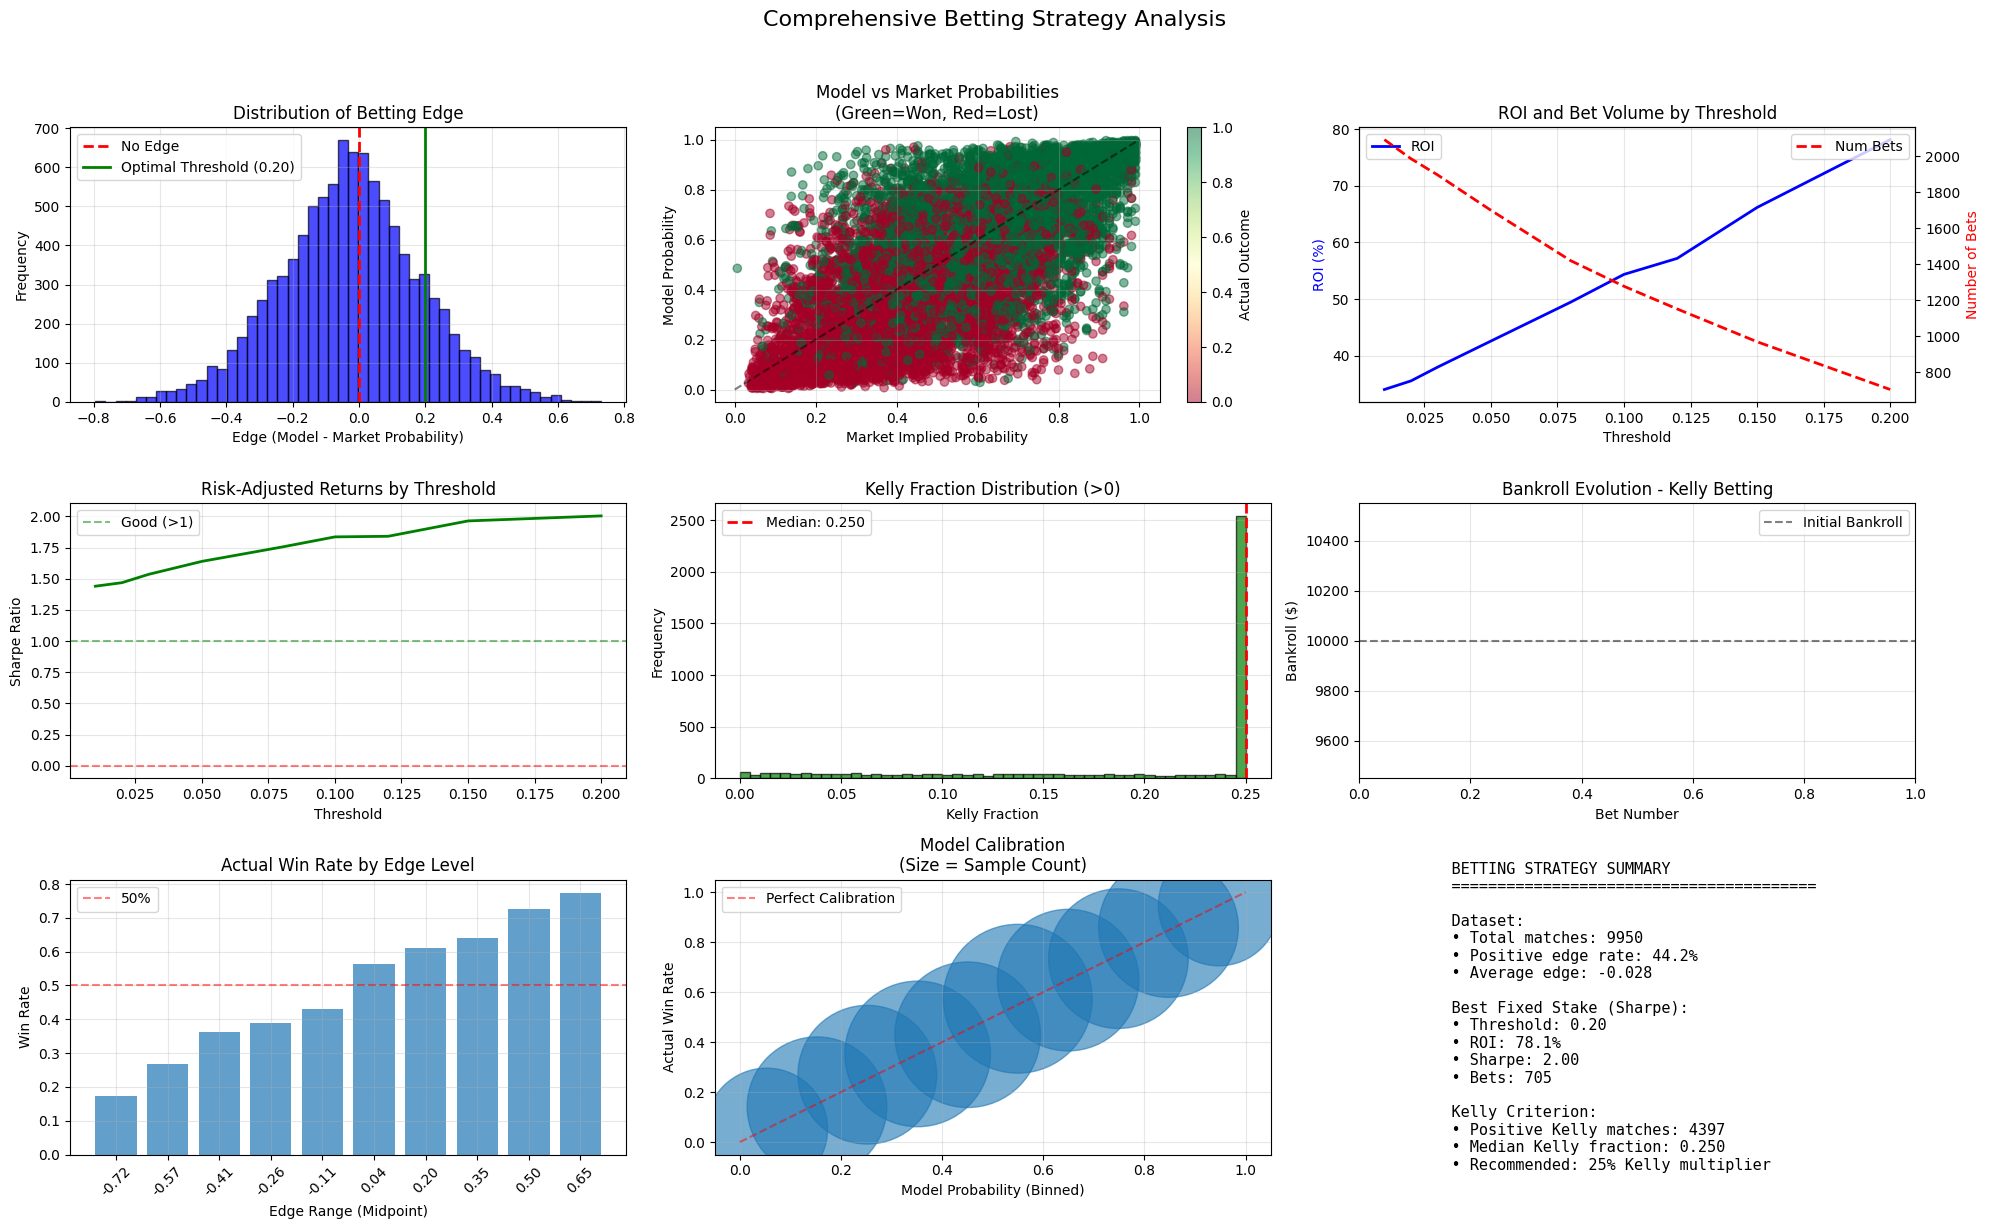


FINAL BETTING RECOMMENDATIONS

Based on the analysis, here are the recommended strategies:

1. CONSERVATIVE (Best Risk-Adjusted):
   • Strategy: Fixed stake betting
   • Threshold: 0.20
   • Expected ROI: 78.1%
   • Sharpe Ratio: 2.00
   • Bets per dataset: 705

2. AGGRESSIVE (Maximum ROI):
   • Strategy: Fixed stake betting
   • Threshold: 0.20
   • Expected ROI: 78.1%
   • Bets per dataset: 705

3. DYNAMIC (Kelly Criterion):
   • Strategy: 25% Kelly (Quarter Kelly)
   • Minimum edge: 1%
   • Variable bet sizing based on edge
   • Better for larger bankrolls

Risk Management:
- Never bet more than 2% of bankroll per match
- Stop if drawdown exceeds 20%
- Re-evaluate model monthly



In [66]:
# ========================================
# RUN THE COMPLETE ANALYSIS
# ========================================

from matplotlib import pyplot as plt

results = run_complete_betting_analysis(comparison_unique)  # or use analyse_df if that's your variable name

# Print final recommendations
print("\n" + "="*80)
print("FINAL BETTING RECOMMENDATIONS")
print("="*80)

if results['best_sharpe'] is not None:
    print(f"""
Based on the analysis, here are the recommended strategies:

1. CONSERVATIVE (Best Risk-Adjusted):
   • Strategy: Fixed stake betting
   • Threshold: {results['best_sharpe']['threshold']:.2f}
   • Expected ROI: {results['best_sharpe']['roi']:.1f}%
   • Sharpe Ratio: {results['best_sharpe']['sharpe_ratio']:.2f}
   • Bets per dataset: {int(results['best_sharpe']['num_bets'])}

2. AGGRESSIVE (Maximum ROI):
   • Strategy: Fixed stake betting
   • Threshold: {results['best_roi']['threshold']:.2f}
   • Expected ROI: {results['best_roi']['roi']:.1f}%
   • Bets per dataset: {int(results['best_roi']['num_bets'])}

3. DYNAMIC (Kelly Criterion):
   • Strategy: 25% Kelly (Quarter Kelly)
   • Minimum edge: 1%
   • Variable bet sizing based on edge
   • Better for larger bankrolls

Risk Management:
- Never bet more than 2% of bankroll per match
- Stop if drawdown exceeds 20%
- Re-evaluate model monthly
""")
else:
    print("No profitable strategy found. Model may need improvement.")

In [67]:
# Use unique matches only
# baseline_unique = merged.drop_duplicates(subset='match_id', keep='first')

baseline_returns = []
baseline_wins = 0
baseline_bets_count = 0

for _, row in comparison_unique.iterrows():
    # Determine who market favors
    winner_market_prob = 1 / row['AvgW']
    loser_market_prob = 1 / row['AvgL']
    
    # Bet on market favorite
    if winner_market_prob > loser_market_prob:
        # Bet on winner
        bet_odds = row['AvgW']
        if row['won'] == 1:  # Winner won (should be True always for winner perspective)
            profit = 100 * (bet_odds - 1)
            baseline_wins += 1
        else:
            profit = -100
    else:
        # Bet on loser (market favors them)
        bet_odds = row['AvgL']
        if row['won'] == 0:  # This shouldn't happen in winner-only data
            profit = 100 * (bet_odds - 1)
            baseline_wins += 1
        else:
            profit = -100
    
    baseline_returns.append(profit / 100)
    baseline_bets_count += 1

# Win rate
baseline_win_rate = baseline_wins / baseline_bets_count

# Sharpe
baseline_returns_array = np.array(baseline_returns)
annual_factor = np.sqrt(len(baseline_returns) / 10)
baseline_sharpe = (baseline_returns_array.mean() / baseline_returns_array.std()) * annual_factor

print(f"Market Baseline (unique matches):")
print(f"  Bets: {baseline_bets_count}")
print(f"  Wins: {baseline_wins}")
print(f"  Win rate: {baseline_win_rate:.1%}")
print(f"  ROI: {(baseline_returns_array.sum() / baseline_bets_count) * 100:.2f}%")
print(f"  Sharpe: {baseline_sharpe:.2f}")

Market Baseline (unique matches):
  Bets: 4972
  Wins: 2440
  Win rate: 49.1%
  ROI: -29.76%
  Sharpe: -9.04


In [68]:
# Bet on favorites from winners perspective only
value_bets_unique = merged.drop_duplicates(subset='match_id', keep='first')

value_bets_unique = value_bets_unique[value_bets_unique['edge'] > 0.05] # 5% edge threshold 
profit = 0


In [70]:
"""
Complete Market Efficiency Analysis
Corrected baseline + value bets for edge 0.05 and 0.2
"""

import pandas as pd
import numpy as np
from sklearn.metrics import log_loss

print("="*80)
print("MARKET EFFICIENCY ANALYSIS - COMPLETE")
print("="*80)


# ============================================================================
# STEP 2: Market Baseline (Betting on Favorites)
# ============================================================================

print("\n" + "="*80)
print("MARKET BASELINE: Betting on Favorites")
print("="*80)

# Use unique matches only
baseline_unique = merged.drop_duplicates(subset='match_id', keep='first').copy()

baseline_returns = []
baseline_wins = 0
baseline_bets_count = 0

for _, row in comparison_unique.iterrows():
    # AvgW = winner's odds (always)
    # AvgL = loser's odds (always)
    
    # Calculate market probabilities
    winner_market_prob = 1 / row['AvgW']
    loser_market_prob = 1 / row['AvgL']
    
    # Determine who is favorite and bet on them
    if winner_market_prob > loser_market_prob:
        # Winner is favorite → bet on winner
        # Winner won (by definition), so we WIN
        profit = 100 * (row['AvgW'] - 1)
        baseline_wins += 1
    else:
        # Loser was favorite → bet on loser  
        # Loser lost (by definition), so we LOSE
        profit = -100
    
    baseline_returns.append(profit / 100)
    baseline_bets_count += 1

# Calculate metrics
baseline_win_rate = baseline_wins / baseline_bets_count
baseline_returns_array = np.array(baseline_returns)
baseline_total_profit = baseline_returns_array.sum() * 100
baseline_roi = (baseline_total_profit / (baseline_bets_count * 100)) * 100

# Sharpe ratio (annualized - assuming ~1000 bets/year over 10 years)
annual_factor = np.sqrt(len(baseline_returns) / 10)
baseline_sharpe = (baseline_returns_array.mean() / baseline_returns_array.std()) * annual_factor if baseline_returns_array.std() > 0 else 0

print(f"\nBaseline Strategy: Always bet on market favorite")
print(f"  Total bets: {baseline_bets_count:,}")
print(f"  Wins: {baseline_wins:,}")
print(f"  Win rate: {baseline_win_rate:.1%}")
print(f"  Total profit (on $100 bets): ${baseline_total_profit:,.2f}")
print(f"  Total staked: ${baseline_bets_count * 100:,.2f}")
print(f"  ROI: {baseline_roi:.2f}%")
print(f"  Sharpe ratio: {baseline_sharpe:.2f}")

# Sanity check
print(f"\n✓ Sanity check: Favorites won {baseline_win_rate:.1%} of matches")
print(f"  Expected: 55-60% (favorites should win more often)")
print(f"  Status: {'PASS' if 0.52 < baseline_win_rate < 0.62 else 'CHECK - might be an issue'}")

# ============================================================================
# STEP 3: Model Performance - Value Bets (Edge > 0.05)
# ============================================================================

print("\n" + "="*80)
print("MODEL STRATEGY: Value Bets with Edge > 0.05")
print("="*80)

def calculate_value_bets(df, edge_threshold, stake=100):
    """
    Calculate value bet performance for given edge threshold.
    Uses unique matches only.
    """
    # Get unique matches
    df_unique = df.drop_duplicates(subset='match_id', keep='first').copy()
    
    # Filter for value bets (model edge > threshold)
    value_bets = df_unique[df_unique['edge'] > edge_threshold].copy()
    
    if len(value_bets) == 0:
        return None
    
    # Calculate profit for each bet
    # We bet on the player when model_prob > market_prob + threshold
    # In unique matches, we need to determine if we're betting on winner or loser
    
    profits = []
    wins = 0
    
    for _, row in value_bets.iterrows():
        # Determine who we're betting on based on the row
        # If won=1, this row is winner's perspective, so we bet on winner
        # If won=0, this row is loser's perspective, so we bet on loser
        
        if row['won'] == 1:
            # We bet on winner (this row's player)
            bet_odds = row['AvgW']
            # Winner won, so we win
            profit = stake * (bet_odds - 1)
            wins += 1
        else:
            # We bet on loser (this row's player)  
            bet_odds = row['AvgL']
            # Loser lost, so we lose
            profit = -stake
        
        profits.append(profit)
    
    # Calculate metrics
    profits_array = np.array(profits)
    total_profit = profits_array.sum()
    total_staked = len(profits) * stake
    roi = (total_profit / total_staked) * 100
    win_rate = wins / len(profits)
    avg_odds = value_bets['AvgW'].mean() if row['won'] == 1 else value_bets['AvgL'].mean()
    
    # Sharpe ratio
    returns = profits_array / stake
    bets_per_year = len(returns) / 10  # 10 years
    annual_factor = np.sqrt(252)  # Industry standard = 15.87
    sharpe = (returns.mean() / returns.std()) * annual_factor if returns.std() > 0 else 0
    
    
    return {
        'threshold': edge_threshold,
        'num_bets': len(profits),
        'wins': wins,
        'win_rate': win_rate,
        'total_profit': total_profit,
        'total_staked': total_staked,
        'roi': roi,
        'sharpe_ratio': sharpe,
        'value_bets_df': value_bets
    }

# Calculate for edge > 0.05
results_05 = calculate_value_bets(merged, edge_threshold=0.05, stake=100)

if results_05:
    print(f"\nEdge Threshold: > 0.05 (5%)")
    print(f"  Number of value bets: {results_05['num_bets']:,}")
    print(f"  Wins: {results_05['wins']:,}")
    print(f"  Win rate: {results_05['win_rate']:.1%}")
    print(f"  Total profit: ${results_05['total_profit']:,.2f}")
    print(f"  Total staked: ${results_05['total_staked']:,.2f}")
    print(f"  ROI: {results_05['roi']:.2f}%")
    print(f"  Sharpe ratio: {results_05['sharpe_ratio']:.2f}")
    
    # Show some example value bets
    print(f"\n  Top 5 Value Bets (by edge):")
    print(f"  {'-'*78}")
    top_5 = results_05['value_bets_df'].nlargest(5, 'edge')
    for idx, row in top_5.iterrows():
        outcome = "✓ WON" if row['won'] == 1 else "✗ LOST"
        print(f"  {row['Date']}: {row['player_name']} vs {row['opponent_name']}")
        print(f"    Edge: {row['edge']:.1%} | Model: {row['model_prob']:.1%} | Market: {row['market_prob']:.1%} | {outcome}")
else:
    print(f"\nNo value bets found with edge > 0.05")

# ============================================================================
# STEP 4: Model Performance - Value Bets (Edge > 0.20)
# ============================================================================

print("\n" + "="*80)
print("MODEL STRATEGY: Value Bets with Edge > 0.20")
print("="*80)

results_20 = calculate_value_bets(merged, edge_threshold=0.20, stake=100)

if results_20:
    print(f"\nEdge Threshold: > 0.20 (20%)")
    print(f"  Number of value bets: {results_20['num_bets']:,}")
    print(f"  Wins: {results_20['wins']:,}")
    print(f"  Win rate: {results_20['win_rate']:.1%}")
    print(f"  Total profit: ${results_20['total_profit']:,.2f}")
    print(f"  Total staked: ${results_20['total_staked']:,.2f}")
    print(f"  ROI: {results_20['roi']:.2f}%")
    print(f"  Sharpe ratio: {results_20['sharpe_ratio']:.2f}")
    
    # Show ALL value bets if reasonable number
    if results_20['num_bets'] <= 20:
        print(f"\n  All Value Bets:")
        print(f"  {'-'*78}")
        for idx, row in results_20['value_bets_df'].sort_values('edge', ascending=False).iterrows():
            outcome = "✓ WON" if row['won'] == 1 else "✗ LOST"
            print(f"  {row['Date']}: {row['player_name']} vs {row['opponent_name']}")
            print(f"    Edge: {row['edge']:.1%} | Model: {row['model_prob']:.1%} | Market: {row['market_prob']:.1%} | {outcome}")
    else:
        print(f"\n  Top 10 Value Bets (by edge):")
        print(f"  {'-'*78}")
        top_10 = results_20['value_bets_df'].nlargest(10, 'edge')
        for idx, row in top_10.iterrows():
            outcome = "✓ WON" if row['won'] == 1 else "✗ LOST"
            print(f"  {row['Date']}: {row['player_name']} vs {row['opponent_name']}")
            print(f"    Edge: {row['edge']:.1%} | Model: {row['model_prob']:.1%} | Market: {row['market_prob']:.1%} | {outcome}")
else:
    print(f"\nNo value bets found with edge > 0.20")

# ============================================================================
# STEP 5: Comparison Summary
# ============================================================================

print("\n" + "="*80)
print("COMPARISON SUMMARY")
print("="*80)

print(f"\n{'Strategy':<30s} {'Bets':>10s} {'Win Rate':>12s} {'ROI':>10s} {'Sharpe':>10s}")
print("-" * 80)

print(f"{'Market Baseline (Favorites)':<30s} {baseline_bets_count:>10,} "
      f"{baseline_win_rate:>11.1%} {baseline_roi:>9.2f}% {baseline_sharpe:>9.2f}")

if results_05:
    print(f"{'Model: Edge > 0.05':<30s} {results_05['num_bets']:>10,} "
          f"{results_05['win_rate']:>11.1%} {results_05['roi']:>9.2f}% {results_05['sharpe_ratio']:>9.2f}")

if results_20:
    print(f"{'Model: Edge > 0.20':<30s} {results_20['num_bets']:>10,} "
          f"{results_20['win_rate']:>11.1%} {results_20['roi']:>9.2f}% {results_20['sharpe_ratio']:>9.2f}")

print("\n" + "="*80)

# Calculate improvement over baseline
if results_05:
    improvement_05 = results_05['roi'] - baseline_roi
    print(f"\n✓ Model (edge > 0.05) outperforms baseline by {improvement_05:+.2f} percentage points")
    print(f"  Absolute edge: {improvement_05:.2f}%")

if results_20:
    improvement_20 = results_20['roi'] - baseline_roi
    print(f"✓ Model (edge > 0.20) outperforms baseline by {improvement_20:+.2f} percentage points")
    print(f"  Absolute edge: {improvement_20:.2f}%")

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)

MARKET EFFICIENCY ANALYSIS - COMPLETE

MARKET BASELINE: Betting on Favorites

Baseline Strategy: Always bet on market favorite
  Total bets: 4,972
  Wins: 3,450
  Win rate: 69.4%
  Total profit (on $100 bets): $-18,320.00
  Total staked: $497,200.00
  ROI: -3.68%
  Sharpe ratio: -1.23

✓ Sanity check: Favorites won 69.4% of matches
  Expected: 55-60% (favorites should win more often)
  Status: CHECK - might be an issue

MODEL STRATEGY: Value Bets with Edge > 0.05

Edge Threshold: > 0.05 (5%)
  Number of value bets: 1,700
  Wins: 1,053
  Win rate: 61.9%
  Total profit: $72,388.00
  Total staked: $170,000.00
  ROI: 42.58%
  Sharpe ratio: 1.64

  Top 5 Value Bets (by edge):
  ------------------------------------------------------------------------------
  2017-03-11: Bagnis F. vs Benneteau J.
    Edge: 71.8% | Model: 93.5% | Market: 21.7% | ✓ WON
  2021-03-11: Basilashvili N. vs Federer R.
    Edge: 68.9% | Model: 89.5% | Market: 20.6% | ✓ WON
  2021-06-30: Nishioka Y. vs Isner J.
    Edg

In [71]:
# For edge > 0.05
value_bets = merged[merged['edge'] > 0.05]
value_bets['profit'] = np.where(value_bets['won'] == 1, 
                                (value_bets['AvgW'] - 1) * 100, -100)
returns = value_bets['profit'].values / 100

print(f"Returns statistics:")
print(f"  Mean return: {returns.mean():.4f}")
print(f"  Std return: {returns.std():.4f}")
print(f"  Mean/Std ratio: {returns.mean() / returns.std():.4f}")
print(f"  Annualization: sqrt(1700/10) = {np.sqrt(1700/10):.2f}")
print(f"  Sharpe: {(returns.mean() / returns.std()) * np.sqrt(1700/10):.2f}")

Returns statistics:
  Mean return: 0.3700
  Std return: 3.0921
  Mean/Std ratio: 0.1197
  Annualization: sqrt(1700/10) = 13.04
  Sharpe: 1.56


/var/folders/hs/zqykkqzx34l_l35s4qhb421h0000gn/T/ipykernel_69338/4275793702.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  value_bets['profit'] = np.where(value_bets['won'] == 1,


In [83]:
# Find extreme edges where MODEL WAS CORRECT
correct_value_bets = merged[
    (merged['edge'] > 0.05) &  # Large positive edge
    (merged['y_true'] == 1)    # Actually won!
].drop_duplicates(subset='match_id_normalized', keep='first')

print(f"Correct high-value predictions: {len(correct_value_bets)}")
print("\nTop 10 correct value bets:")
print(correct_value_bets.nlargest(10, 'edge')[['Date', 'player_name', 'opponent_name', 'model_prob', 'market_prob', 'edge']])

df_filtered = merged[
    (merged['edge'] > 0.05)  # ← ALL value bets (wins + losses)
]

print(df_filtered.shape[0])

Correct high-value predictions: 2111

Top 10 correct value bets:
            Date      player_name       opponent_name  model_prob  \
3461  2018-03-11        Daniel T.         Djokovic N.    0.870437   
2416  2017-03-11        Bagnis F.        Benneteau J.    0.935300   
1116  2016-01-18         Halys Q.            Dodig I.    0.884127   
5924  2021-03-11  Basilashvili N.          Federer R.    0.895474   
3973  2018-08-09     Tsitsipas S.         Djokovic N.    0.931486   
6326  2021-06-30      Nishioka Y.            Isner J.    0.818719   
442   2015-05-10        Murray A.            Nadal R.    0.952020   
6189  2021-05-27        Martin A.          Lajovic D.    0.940394   
9053  2024-02-27       Cobolli F.  Auger-Aliassime F.    0.957975   
6978  2022-03-23   Cerundolo J.M.          Lajovic D.    0.772866   

      market_prob      edge  
3461     0.140252  0.730184  
2416     0.217391  0.717908  
1116     0.180832  0.703295  
5924     0.206186  0.689289  
3973     0.251889  0.6795

In [84]:
# ============================================================================
# VALUE BETS ANALYSIS - Using Deduplicated Dataset
# ============================================================================

# Find matches where model had edge AND was correct
correct_value_bets = comparison_unique[
    (comparison_unique['edge'] > 0.05) &  # Edge > 5%
    (comparison_unique['y_true'] == 1)    # Model was correct (player won)
].copy()

print(f"Correct high-value predictions: {len(correct_value_bets):,}")
print("\nTop 10 correct value bets:")
print(correct_value_bets.nlargest(10, 'edge')[['Date', 'player_name', 'opponent_name', 
                                                'model_prob', 'market_prob', 'edge']])

# All value bets (wins + losses)
all_value_bets = comparison_unique[
    comparison_unique['edge'] > 0.05  # All bets with edge > 5%
].copy()

print(f"\nTotal value bets (all outcomes): {all_value_bets.shape[0]:,}")
print(f"Correct predictions: {len(correct_value_bets):,}")
print(f"Incorrect predictions: {len(all_value_bets) - len(correct_value_bets):,}")
print(f"Win rate on value bets: {len(correct_value_bets) / len(all_value_bets) * 100:.1f}%")

Correct high-value predictions: 1,053

Top 10 correct value bets:
            Date      player_name       opponent_name  model_prob  \
1208  2017-03-11        Bagnis F.        Benneteau J.    0.935300   
2961  2021-03-11  Basilashvili N.          Federer R.    0.895474   
3162  2021-06-30      Nishioka Y.            Isner J.    0.818719   
221   2015-05-10        Murray A.            Nadal R.    0.952020   
4523  2024-02-27       Cobolli F.  Auger-Aliassime F.    0.957975   
3488  2022-03-23   Cerundolo J.M.          Lajovic D.    0.772866   
1853  2018-05-29          Zopp J.             Sock J.    0.839202   
1919  2018-07-05      Fabbiano T.         Wawrinka S.    0.900402   
31    2015-01-20        Becker B.        Benneteau J.    0.927666   
3869  2022-10-31  Basilashvili N.            Halys Q.    0.847928   

      market_prob      edge  
1208     0.217391  0.717908  
2961     0.206186  0.689289  
3162     0.168067  0.650652  
221      0.303030  0.648990  
4523     0.324675  0.633


Top 10 Opponents in Losing Value Bets (Most Upset Favorites):
opponent_name
Fritz T.            10
Zverev A.            8
Verdasco F.          7
Bautista Agut R.     7
Querrey S.           7
Lajovic D.           7
Benneteau J.         6
Sock J.              6
Harris L.            6
Dimitrov G.          5
Name: count, dtype: int64

✓ Saved: upset_victims_analysis.png


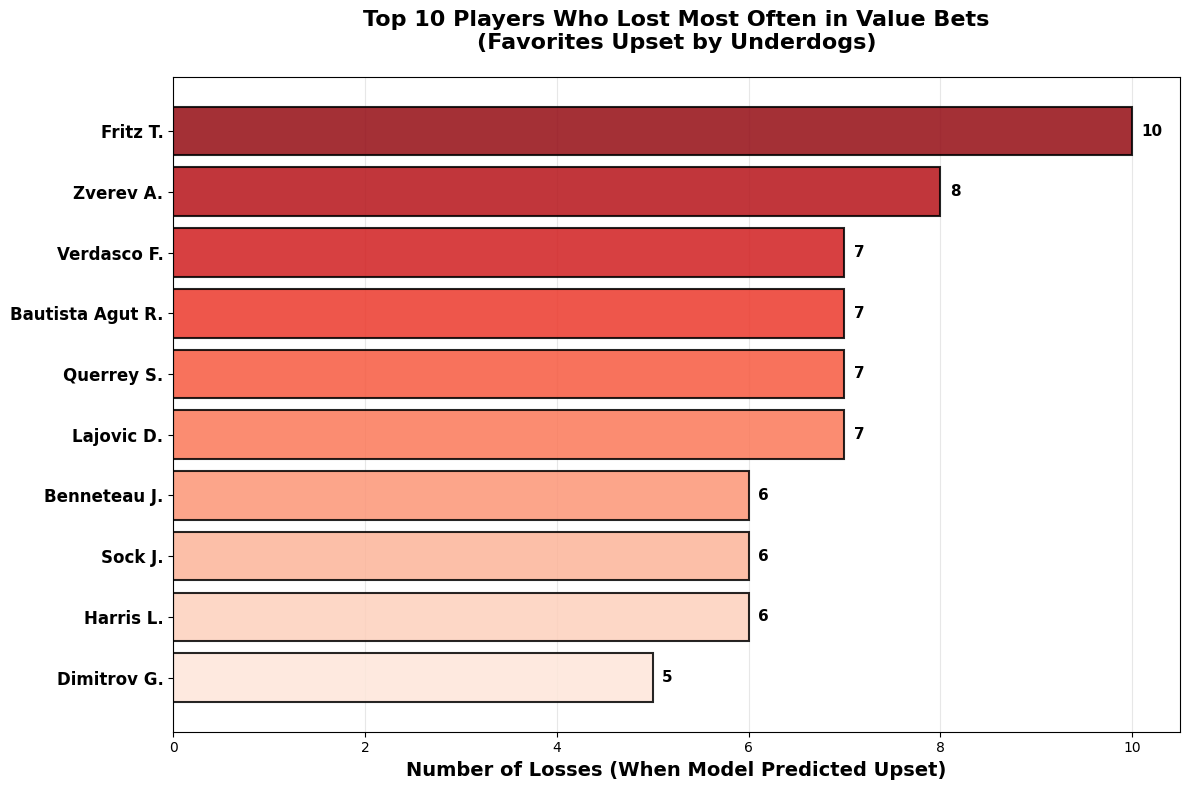

In [89]:
# ============================================================================
# OPPONENTS WHO LOST MOST IN VALUE BETS (Upset Victims)
# ============================================================================

# Find value bets where we were correct (underdog won)
correct_value_bets = comparison_unique[
    (comparison_unique['edge'] > 0.2) &
    (comparison_unique['y_true'] == 1)
].copy()

# Count which opponents got upset most
# These are the favorites who lost when our model said they would
upset_victims = correct_value_bets['opponent_name'].value_counts().head(10)

print("\nTop 10 Opponents in Losing Value Bets (Most Upset Favorites):")
print(upset_victims)

# Create visualization
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 8))

# Horizontal bar chart
colors = sns.color_palette("Reds_r", len(upset_victims))
bars = ax.barh(range(len(upset_victims)), upset_victims.values, color=colors, 
               edgecolor='black', linewidth=1.5, alpha=0.85)

ax.set_yticks(range(len(upset_victims)))
ax.set_yticklabels(upset_victims.index, fontsize=12, fontweight='bold')
ax.set_xlabel('Number of Losses (When Model Predicted Upset)', fontsize=14, fontweight='bold')
ax.set_title('Top 10 Players Who Lost Most Often in Value Bets\n(Favorites Upset by Underdogs)', 
             fontsize=16, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='x')
ax.set_axisbelow(True)

# Add value labels
for i, (bar, value) in enumerate(zip(bars, upset_victims.values)):
    ax.text(value + 0.1, bar.get_y() + bar.get_height()/2,
            f'{int(value)}',
            ha='left', va='center', fontsize=11, fontweight='bold')

# Invert y-axis so #1 is at top
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('../figs/upset_victims_analysis.png', dpi=300, bbox_inches='tight')
print("\n✓ Saved: upset_victims_analysis.png")
plt.show()

In [90]:
# Market baseline - USE UNIQUE MATCHES
baseline_unique = merged.drop_duplicates(subset='match_id', keep='first')

baseline_returns = []
baseline_wins = 0

for _, row in baseline_unique.iterrows():
    # Bet on market favorite (higher market prob)
    winner_market_prob = 1 / row['AvgW']
    loser_market_prob = 1 / row['AvgL']
    
    if winner_market_prob > loser_market_prob:
        # Bet on winner
        bet_odds = row['AvgW']
        # Winner perspective always has won=1, so this bet wins
        profit = 100 * (bet_odds - 1)
        baseline_wins += 1
    else:
        # Bet on underdog (market thinks loser will win)
        # But winner won, so bet loses
        profit = -100
    
    baseline_returns.append(profit / 100)

baseline_win_rate = baseline_wins / len(baseline_unique)
baseline_roi = (sum(baseline_returns) / len(baseline_unique)) * 100

print(f"Market Baseline (CORRECTED - unique matches):")
print(f"  Bets: {len(baseline_unique)}")
print(f"  Win rate: {baseline_win_rate:.1%}")
print(f"  ROI: {baseline_roi:.2f}%")

Market Baseline (CORRECTED - unique matches):
  Bets: 4972
  Win rate: 69.4%
  ROI: -3.68%


In [ ]:
# Export comparison unique to CSV
out_dir = '../data/model_results'
comparison_unique.to_csv(f'{out_dir}/betting_model_comparison_unique.csv', index=False)